# CP2 — Generate Grids: the diversity-stage submission builder

Executes the diversity-stage `plan.md` (phases **G0** and **G2** here; G3/G4 follow). The
regression notebooks are frozen; the winning model classes are copied in below (from
`improve_regressor_beyond_joel.ipynb`, commit d8a5fdc). Strategy: **spread first, validate
second** — the inverse of Joel's generate-valid-then-spread. Number to beat: **0.7566**
(Joel's soft-rule anneal, 8 Nov); ceiling for any 100 grids: 0.808.


In [43]:
# Bootstrap - runs both on Colab and locally in the ps2 repo.
#
# Colab clones the course repo into /content. Locally we reuse the clone that
# ./setup_data.sh puts in data/cp2-repo (gitignored: ~70 MB of course data that
# is not ours to commit). Either way we chdir into it, because utils_public.py
# resolves "datasets/..." and "assets/..." relative to the working directory.
import os
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
COURSE_REPO = "https://github.com/decode-mit/2155-CP2-2026.git"


def _ps2_root(start):
    """Walk up from `start` to the ps2 repo root (the dir holding environment.yml)."""
    d = os.path.abspath(start)
    while True:
        if os.path.exists(os.path.join(d, "environment.yml")):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise RuntimeError(f"could not find the ps2 repo root above {start}")
        d = parent


if IN_COLAB:
    COURSE_ROOT = "/content/2155-CP2-2026"
    SUBMISSION_DIR = "/content/submissions"
    PS2_ROOT = "/content"
else:
    PS2_ROOT = _ps2_root(os.getcwd())
    COURSE_ROOT = os.path.join(PS2_ROOT, "data", "cp2-repo")
    SUBMISSION_DIR = os.path.join(PS2_ROOT, "submissions")

if not os.path.isdir(COURSE_ROOT):
    subprocess.run(["git", "clone", "--depth", "1", COURSE_REPO, COURSE_ROOT], check=True)

os.chdir(COURSE_ROOT)
sys.path.insert(0, COURSE_ROOT)
sys.path.insert(0, PS2_ROOT)  # for joel_features.py at the ps2 repo root
os.makedirs(SUBMISSION_DIR, exist_ok=True)

from utils_public import *

CAND_DIR = os.path.join(PS2_ROOT, "data", "candidates")  # scratch sets (gitignored)
os.makedirs(CAND_DIR, exist_ok=True)

print(f"course data: {COURSE_ROOT}")
print(f"submissions: {SUBMISSION_DIR}")
print(f"candidates:  {CAND_DIR}")


course data: /Users/fb/repos/2.156-ps2/data/cp2-repo
submissions: /Users/fb/repos/2.156-ps2/submissions
candidates:  /Users/fb/repos/2.156-ps2/data/candidates


## Load data
500k grids; each advisor labeled 5k of them (1%). `ADVISOR_NAMES` indexes columns of `ratings`.


In [44]:
import numpy as np
import pandas as pd

grids = load_grids()
ratings = np.load("datasets/scores.npy")
ADVISOR_NAMES = ["Wellness", "Tax", "Transportation", "Business"]

print(grids.shape, ratings.shape)
print("labels per advisor:", (~np.isnan(ratings)).sum(axis=0))


(500000, 7, 7) (500000, 4)
labels per advisor: [5000 5000 5000 5000]


# Phase G0 — Frozen validity gate + scoring plumbing

## Models (copied from the regression notebook)

The adopted lineup: **B2 boundary-weighted LGBM** for Wellness / Transportation / Business
(Wellness additionally gets the 245 one-hot cells), **plain LGBM** for Tax. Copied verbatim from
`improve_regressor_beyond_joel.ipynb` (commit d8a5fdc), with one addition: a `seed` argument so
the gate can be an ensemble of refits.


In [45]:
import lightgbm as lgb
import joel_features as jf

# Joel's exact settings (joel_dev validity.py GBM_PARAMS; set by hand, never tuned on data)
GBM_PARAMS = {
    "n_estimators": 600,
    "learning_rate": 0.03,
    "num_leaves": 31,
    "subsample": 0.8,
    "subsample_freq": 1,
    "colsample_bytree": 0.8,
    "random_state": 0,
    "verbose": -1,
}

VALID_THRESHOLD = 0.75


def lgbm(seed=0):
    return lgb.LGBMRegressor(**{**GBM_PARAMS, "random_state": seed})


class BoundaryWeightedLGBM:
    """B2: Gaussian sample weights centred on the 0.75 validity threshold."""

    def __init__(self, sigma=0.12, floor=0.25, seed=0):
        self.sigma, self.floor, self.seed = sigma, floor, seed

    def fit(self, X, y):
        w = self.floor + (1 - self.floor) * np.exp(
            -0.5 * ((y - VALID_THRESHOLD) / self.sigma) ** 2)
        self.model = lgb.LGBMRegressor(**{**GBM_PARAMS, "random_state": self.seed})
        self.model.fit(X, y, sample_weight=w)
        return self

    def predict(self, X):
        return self.model.predict(X)


def featurize(grid_arr):
    eng = jf.engineered(grid_arr)
    return {"eng": eng, "eng_oh": np.hstack([eng, jf.onehot(grid_arr)])}


FEATURE_OF = {"Wellness": "eng_oh", "Tax": "eng",
              "Transportation": "eng", "Business": "eng"}
MODEL_OF = {"Wellness": BoundaryWeightedLGBM, "Tax": lgbm,
            "Transportation": BoundaryWeightedLGBM, "Business": BoundaryWeightedLGBM}


def make_model(advisor, seed=0):
    return MODEL_OF[advisor](seed=seed)


## The gate, part 1: `rate()` — an ensemble of 3 refits per advisor

Trained on **all 5,000 labels** per advisor (no holdout — the OOF cutoff cell below is where
honesty lives). `spread`, the refits' disagreement, is our per-grid uncertainty signal: it grows
on grids unlike the training data, which is exactly where our constructive designs will live.


In [46]:
import time

ENSEMBLE_SEEDS = (0, 1, 2)

t0 = time.time()
ENSEMBLES = {}
for ai, adv in enumerate(ADVISOR_NAMES):
    g_sub, y = select_rated_subset(grids, ratings[:, ai])
    X = featurize(g_sub)[FEATURE_OF[adv]]
    ENSEMBLES[adv] = [make_model(adv, s).fit(X, y) for s in ENSEMBLE_SEEDS]
print(f"trained {4 * len(ENSEMBLE_SEEDS)} models on all labels in {time.time() - t0:.0f}s")


def rate(grid_arr):
    """(n,7,7) -> (pred, spread), each (n,4) in ADVISOR_NAMES order:
    mean and std over the ensemble refits."""
    F = featurize(np.asarray(grid_arr))
    pred = np.empty((len(grid_arr), 4))
    spread = np.empty_like(pred)
    for ai, adv in enumerate(ADVISOR_NAMES):
        p = np.stack([m.predict(F[FEATURE_OF[adv]]) for m in ENSEMBLES[adv]])
        pred[:, ai] = p.mean(axis=0)
        spread[:, ai] = p.std(axis=0)
    return pred, spread


p, s = rate(grids[:200])
print(f"rate() check: {p.shape}, pred range [{p.min():.2f}, {p.max():.2f}], "
      f"mean spread {s.mean():.4f}")


trained 12 models on all labels in 26s
rate() check: (200, 4), pred range [-0.14, 1.06], mean spread 0.0095


## The gate, part 2: cutoffs at 98% precision + the `approve()` bar

Per advisor: 5-fold OOF predictions × 3 shuffles; the cutoff is the *predicted* score of the
deepest grid still certified while cumulative precision ≥ 98% (so cutoffs sit above 0.75), mean
over shuffles. The operating bar is `cutoff + margin (+ kappa·spread)`:

- `margin` — the global cushion. 0.06 is Joel's scoreboard-proven default (hard rule → 100/100);
  our grids stray farther off-distribution than his, so start there.
- `kappa` — per-grid uncertainty gate (0 = off): grids the ensemble disagrees on must clear a
  higher bar.


In [47]:
from sklearn.model_selection import KFold


def cutoff_at_precision(oof, y, target=0.98):
    """Predicted score at the deepest ranking depth where the certified pool
    stays >= target precision."""
    order = np.argsort(-oof)
    valid = (y[order] >= VALID_THRESHOLD)
    cum_precision = np.cumsum(valid) / np.arange(1, len(valid) + 1)
    ok = np.where(cum_precision >= target)[0]
    if not ok.size:
        return np.inf
    return oof[order][ok[-1]]


t0 = time.time()
CUTS = np.empty(4)
for ai, adv in enumerate(ADVISOR_NAMES):
    g_sub, y = select_rated_subset(grids, ratings[:, ai])
    X = featurize(g_sub)[FEATURE_OF[adv]]
    cuts_s = []
    for shuffle in (0, 1, 2):
        oof = np.empty(len(y))
        for tr, te in KFold(5, shuffle=True, random_state=shuffle).split(X):
            m = make_model(adv).fit(X[tr], y[tr])
            oof[te] = m.predict(X[te])
        cuts_s.append(cutoff_at_precision(oof, y))
    CUTS[ai] = np.mean(cuts_s)
    print(f"{adv:<16} cutoff = {CUTS[ai]:.3f}  (per shuffle: {np.round(cuts_s, 3)})")
print(f"({time.time() - t0:.0f}s)")


def bar(margin=0.06, spread=None, kappa=0.0):
    b = CUTS + margin
    if spread is not None and kappa:
        b = b + kappa * spread
    return b


def approve(pred, spread=None, margin=0.06, kappa=0.0):
    return np.all(pred >= bar(margin, spread, kappa), axis=1)


def total_shortfall(pred, b):
    """Per grid: how far below the bar, summed over advisors (0 = clears everything)."""
    return np.maximum(0.0, b - pred).sum(axis=1)


Wellness         cutoff = 0.798  (per shuffle: [0.794 0.798 0.802])
Tax              cutoff = 0.770  (per shuffle: [0.772 0.768 0.77 ])
Transportation   cutoff = 0.770  (per shuffle: [0.769 0.768 0.772])
Business         cutoff = 0.758  (per shuffle: [0.76  0.756 0.757])
(125s)


## Scorers

`diversity_score` is the course's own implementation (imported from `utils_public`, never
reimplemented). `fast_score` is the loop-friendly version on a precomputed distance matrix,
asserted to match exactly; `row_after_change` updates one grid's distance row in O(n) when a
single cell changes.


In [48]:
def flat_of(grid_arr):
    return np.asarray(grid_arr).reshape(len(grid_arr), -1)


def dist_matrix(flat):
    return (flat[:, None, :] != flat[None, :, :]).mean(axis=2)


def fast_score(D, k=10, N=100):
    Dm = D.copy()
    np.fill_diagonal(Dm, np.inf)
    knn = np.partition(Dm, k, axis=1)[:, :k]
    return knn.mean(axis=1).sum() / N


def row_after_change(flat, D, i, c, v):
    """Distance row of grid i after cell c -> value v, in O(n)."""
    delta = ((flat[:, c] == flat[i, c]).astype(float) - (flat[:, c] == v)) / flat.shape[1]
    row = D[i] + delta
    row[i] = 0.0
    return row


_check = np.random.default_rng(0).integers(0, 5, (100, 7, 7))
assert abs(fast_score(dist_matrix(flat_of(_check))) - diversity_score(_check)) < 1e-9
print("fast_score matches the course diversity_score exactly")


fast_score matches the course diversity_score exactly


## Sanity checks (a–d)

(a) diversity of 100 random dataset grids; (b) 100 random *uniform* grids ≈ 0.80 (ceiling
0.808) — this is why "spread first" starts from random grids; (c) `approve` pass rates on a
20k dataset sample, which should be consistent with the regression notebook's recall/yield;
(d) an end-to-end dry run — greedy farthest-point 100 from the approved pool, scored, format-
checked, saved to the scratch candidates dir (NOT `submissions/`).


In [49]:
rng = np.random.default_rng(0)

idx = rng.choice(len(grids), 100, replace=False)
print(f"(a) diversity of 100 random dataset grids: {diversity_score(grids[idx]):.4f}")

uni = rng.integers(0, 5, (100, 7, 7))
print(f"(b) diversity of 100 random uniform grids: {diversity_score(uni):.4f}  (ceiling 0.808)")

sample = grids[rng.choice(len(grids), 20_000, replace=False)]
sample_pred, sample_spread = rate(sample)
per_adv = (sample_pred >= CUTS).mean(axis=0)
print("(c) pass rate at margin 0, per advisor:", dict(zip(ADVISOR_NAMES, per_adv.round(3))))
print(f"    joint @ margin 0: {approve(sample_pred, margin=0).mean():.3f}"
      f"   joint @ margin 0.06: {approve(sample_pred, margin=0.06).mean():.3f}")


def greedy_maxmin(grid_arr, n=100, seed=0):
    """Farthest-point pick of n grids by Hamming distance."""
    flat = flat_of(grid_arr)
    picked = [int(np.random.default_rng(seed).integers(len(flat)))]
    dmin = (flat != flat[picked[0]]).mean(axis=1)
    for _ in range(n - 1):
        nxt = int(np.argmax(dmin))
        picked.append(nxt)
        dmin = np.minimum(dmin, (flat != flat[nxt]).mean(axis=1))
    return np.asarray(picked)


def submission_checks(arr):
    arr = np.asarray(arr)
    assert arr.shape == (100, 7, 7), f"bad shape {arr.shape}"
    assert np.issubdtype(arr.dtype, np.integer), f"bad dtype {arr.dtype}"
    assert arr.min() >= 0 and arr.max() <= 4, "values outside 0-4"
    assert len(np.unique(flat_of(arr), axis=0)) == 100, "duplicate grids"
    return arr


def save_candidate(arr, name):
    path = os.path.join(CAND_DIR, f"{name}.npy")
    np.save(path, submission_checks(arr))
    print(f"saved candidate {path}  (diversity {diversity_score(np.asarray(arr)):.4f})")
    return path


def save_submission(arr):
    """The real thing: writes submissions/submission_<ts>.npy (upload the .npy, NEVER a json)."""
    from datetime import datetime
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    path = os.path.join(SUBMISSION_DIR, f"submission_{ts}.npy")
    np.save(path, submission_checks(arr))
    print(f"SAVED SUBMISSION {path}")
    return path


pool = sample[approve(sample_pred, margin=0.06)]
if len(pool) < 100:
    print(f"(d) only {len(pool)} sample grids approved at margin 0.06; "
          f"falling back to the 500 with the best worst-advisor margin")
    pool = sample[np.argsort(-(sample_pred - CUTS).min(axis=1))[:500]]
dry = pool[greedy_maxmin(pool)].astype(np.int64)
print(f"(d) dry run: pool {len(pool)}, ", end="")
save_candidate(dry, "dryrun_dataset_maxmin")


(a) diversity of 100 random dataset grids: 0.6864
(b) diversity of 100 random uniform grids: 0.6998  (ceiling 0.808)
(c) pass rate at margin 0, per advisor: {'Wellness': np.float64(0.156), 'Tax': np.float64(0.209), 'Transportation': np.float64(0.2), 'Business': np.float64(0.229)}
    joint @ margin 0: 0.002   joint @ margin 0.06: 0.001
(d) only 17 sample grids approved at margin 0.06; falling back to the 500 with the best worst-advisor margin
(d) dry run: pool 500, saved candidate /Users/fb/repos/2.156-ps2/data/candidates/dryrun_dataset_maxmin.npy  (diversity 0.7093)


'/Users/fb/repos/2.156-ps2/data/candidates/dryrun_dataset_maxmin.npy'

# Phase G2 — Constructive design: spread first, repair second

Joel made valid grids and then pushed them apart; validity constrained every push (hard-rule
annealing plateaued ~0.742–0.734). We invert it: start from a set already near the diversity
ceiling, then make each grid valid with the fewest, least diversity-damaging edits.

## Step 1 — a near-ceiling spread set (validity ignored)

Random uniform grids start ≈ 0.80; a short pure-numpy anneal pushes toward 0.808. No models
involved — this runs in seconds-to-minutes.


In [50]:
def spread_anneal(grid_set, steps=200_000, seed=0, T0=2e-4, T1=1e-6, report=50_000):
    """Push the set toward the diversity ceiling, ignoring validity entirely."""
    g = np.asarray(grid_set).copy()
    flat = flat_of(g)
    D = dist_matrix(flat)
    score = fast_score(D)
    r = np.random.default_rng(seed)
    T = T0 * (T1 / T0) ** (np.arange(steps) / steps)
    for t in range(steps):
        i, c, v = int(r.integers(len(g))), int(r.integers(49)), int(r.integers(5))
        if v == flat[i, c]:
            continue
        row = row_after_change(flat, D, i, c, v)
        D2 = D.copy()
        D2[i], D2[:, i] = row, row
        new = fast_score(D2)
        if new - score >= T[t] * np.log(r.random() + 1e-300):
            flat[i, c] = v
            D, score = D2, new
        if report and (t + 1) % report == 0:
            print(f"  step {t + 1:>7,}: {score:.4f}")
    return g, score


SPREAD_SET = np.random.default_rng(1).integers(0, 5, (100, 7, 7))
print(f"random uniform start: {diversity_score(SPREAD_SET):.4f}")
t0 = time.time()
SPREAD_SET, _ = spread_anneal(SPREAD_SET, steps=200_000)
print(f"after spread anneal:  {diversity_score(SPREAD_SET):.4f}  "
      f"(ceiling 0.808, {time.time() - t0:.0f}s)")


random uniform start: 0.6988
  step 100,000: 0.7523
  step 150,000: 0.7588
after spread anneal:  0.7641  (ceiling 0.808, 7s)


## Step 2 — diversity-aware repair to validity

Per grid: batch-rate all 196 one-cell variants in one `rate()` call, apply the variant with the
best `shortfall_reduction + beta · own_10NN_diversity_change` (only shortfall-reducing variants
qualify); a 3-cell random kick breaks dead ends. Hill-climb mechanics credited to Joel's
`generate.py`; the diversity-aware objective and the spread-first starting point are ours.

Knobs: `margin`/`kappa` set the bar; `beta` trades repair speed against diversity retention
(0 = pure Joel-style repair). If repair stalls badly from fully random starts, the plan's
fallback is to re-run Step 1 starting from heavily-mutated dataset grids.


In [51]:
def one_cell_variants(grid):
    """All 196 single-cell changes of one grid -> (variants (196,7,7), cells, vals)."""
    f = grid.reshape(-1)
    cells, vals = [], []
    for c in range(49):
        for v in range(5):
            if v != f[c]:
                cells.append(c)
                vals.append(v)
    cells, vals = np.array(cells), np.array(vals)
    variants = np.repeat(f[None], len(cells), axis=0)
    variants[np.arange(len(cells)), cells] = vals
    return variants.reshape(-1, 7, 7), cells, vals


def repair_set(grid_set, margin=0.06, kappa=0.0, beta=0.1, max_steps=300, seed=0,
               report_every=10):
    """Edit every grid until it clears the bar, spending as little diversity as possible.

    The diversity term tracks only the edited grid's own 10-NN mean (its neighbours' means
    shift too — good enough as a repair heuristic; the exact course score is what we report
    at the end). Returns (repaired grids, stats)."""
    g = np.asarray(grid_set).copy()
    n = len(g)
    flat = g.reshape(n, -1)  # view: edits via flat update g too
    D = dist_matrix(flat)
    r = np.random.default_rng(seed)
    pred, spread = rate(g)
    stats = {"edits": np.zeros(n, int), "kicks": np.zeros(n, int), "unrepaired": []}

    def bar_of(p, s):
        return bar(margin, s, kappa)

    t0 = time.time()
    for i in range(n):
        for _ in range(max_steps):
            sf_i = total_shortfall(pred[i:i + 1], bar_of(pred[i:i + 1], spread[i:i + 1]))[0]
            if sf_i <= 0:
                break
            variants, cells, vals = one_cell_variants(g[i])
            vp, vs = rate(variants)
            sf = total_shortfall(vp, bar_of(vp, vs))

            # own-row 10-NN mean for every variant, vectorized
            old_match = flat[:, cells] == flat[i, cells][None, :]        # (n, 196)
            new_match = flat[:, cells] == vals[None, :]                  # (n, 196)
            rows_new = D[i][:, None] + (old_match.astype(float) - new_match) / flat.shape[1]
            rows_new[i, :] = np.inf
            mean10_new = np.sort(rows_new, axis=0)[:10].mean(axis=0)     # (196,)
            row_cur = D[i].copy()
            row_cur[i] = np.inf
            mean10_cur = np.sort(row_cur)[:10].mean()

            objective = (sf_i - sf) + beta * (mean10_new - mean10_cur)
            qualify = sf < sf_i - 1e-12
            if not qualify.any():
                for c in r.choice(49, 3, replace=False):                 # dead end: kick
                    flat[i, c] = r.integers(5)
                row = (flat != flat[i]).mean(axis=1)
                row[i] = 0.0
                D[i], D[:, i] = row, row
                pred[i], spread[i] = (x[0] for x in rate(g[i:i + 1]))
                stats["kicks"][i] += 1
                continue
            k = int(np.argmax(np.where(qualify, objective, -np.inf)))
            flat[i, cells[k]] = vals[k]
            row = rows_new[:, k].copy()
            row[i] = 0.0
            D[i], D[:, i] = row, row
            pred[i], spread[i] = vp[k], vs[k]
            stats["edits"][i] += 1
        else:
            stats["unrepaired"].append(i)
        if report_every and (i + 1) % report_every == 0:
            print(f"  grid {i + 1:>3}/{n}: {stats['edits'][:i + 1].sum()} edits, "
                  f"{stats['kicks'][:i + 1].sum()} kicks, {time.time() - t0:.0f}s")
    return g, stats


In [28]:
REPAIR_MARGIN = 0.06
BETA = 0.1

t0 = time.time()
G2_SET, g2_stats = repair_set(SPREAD_SET, margin=REPAIR_MARGIN, beta=BETA)
g2_pred, g2_spread = rate(G2_SET)
ok = approve(g2_pred, margin=REPAIR_MARGIN)

print(f"\nrepair took {time.time() - t0:.0f}s | edits {g2_stats['edits'].sum()}"
      f" (per grid: median {int(np.median(g2_stats['edits']))},"
      f" max {g2_stats['edits'].max()}) | kicks {g2_stats['kicks'].sum()}"
      f" | unrepaired {g2_stats['unrepaired']}")
print(f"all grids clear bar at margin {REPAIR_MARGIN}: {ok.all()}"
      f"   (worst margin above cuts: {(g2_pred - CUTS).min():.3f})")
print(f"diversity: spread set {diversity_score(SPREAD_SET):.4f}"
      f" -> repaired {diversity_score(G2_SET):.4f}   (Joel to beat: 0.7566)")
print(f"max ensemble spread in the set: {g2_spread.max():.3f}")

save_candidate(G2_SET.astype(np.int64), f"g2_repaired_m{REPAIR_MARGIN:g}")


  grid  10/100: 184 edits, 20 kicks, 5s
  grid  20/100: 336 edits, 29 kicks, 9s
  grid  30/100: 554 edits, 56 kicks, 15s
  grid  40/100: 694 edits, 64 kicks, 19s
  grid  50/100: 917 edits, 94 kicks, 25s
  grid  60/100: 1064 edits, 103 kicks, 29s
  grid  70/100: 1227 edits, 112 kicks, 33s
  grid  80/100: 1397 edits, 124 kicks, 37s
  grid  90/100: 1597 edits, 144 kicks, 43s
  grid 100/100: 1779 edits, 158 kicks, 47s

repair took 47s | edits 1779 (per grid: median 16, max 49) | kicks 158 | unrepaired []
all grids clear bar at margin 0.06: True   (worst margin above cuts: 0.060)
diversity: spread set 0.7641 -> repaired 0.6911   (Joel to beat: 0.7566)
max ensemble spread in the set: 0.027
saved candidate /Users/fb/repos/2.156-ps2/data/candidates/g2_repaired_m0.06.npy  (diversity 0.6911)


'/Users/fb/repos/2.156-ps2/data/candidates/g2_repaired_m0.06.npy'

## G2 diagnostics — visualize and validate the repaired set

Four checks, in order of importance:
1. **Margins** — where each grid sits relative to each advisor's bar (repair stops *at* the bar
   by design, so expect a pile-up at +0.06; G3's job is to keep them above it while spreading).
2. **Off-distribution check** — ensemble disagreement (spread) on our constructive grids vs
   ordinary dataset grids. If the two distributions overlap, the models aren't being asked to
   extrapolate wildly and the 98%-precision calibration is more believable.
3. **Diversity anatomy** — each grid's mean distance to its 10 nearest neighbours, before and
   after repair (the score is the mean of this curve). Shows *where* repair spent diversity.
4. **Novelty** — distance from each G2 grid to its nearest dataset grid, vs how far dataset
   grids are from each other. Quantifies how far off-distribution we actually are.

Plus a gallery of the first 8 maps (eyeball check: do they look like city districts or noise?).


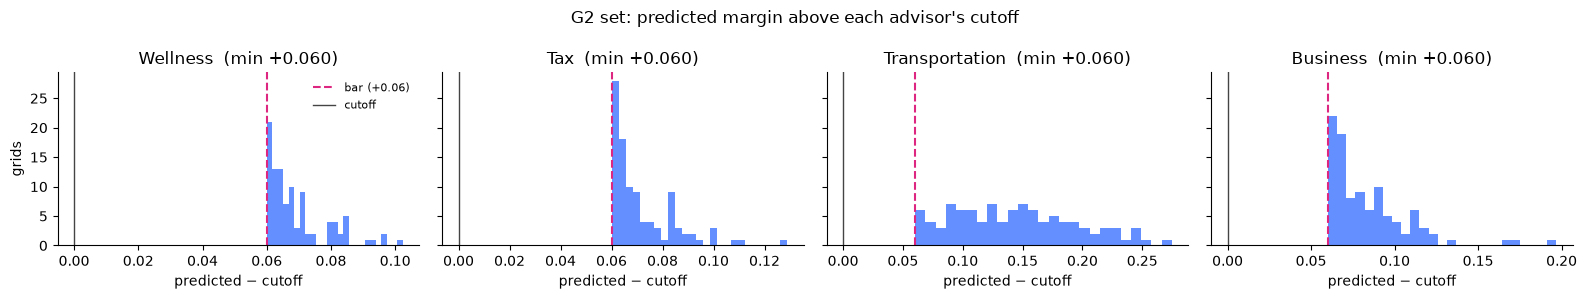

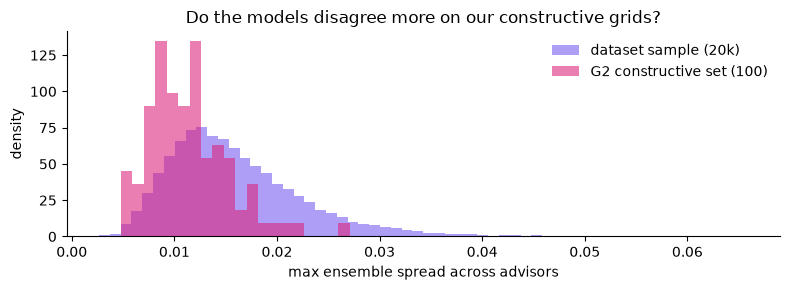

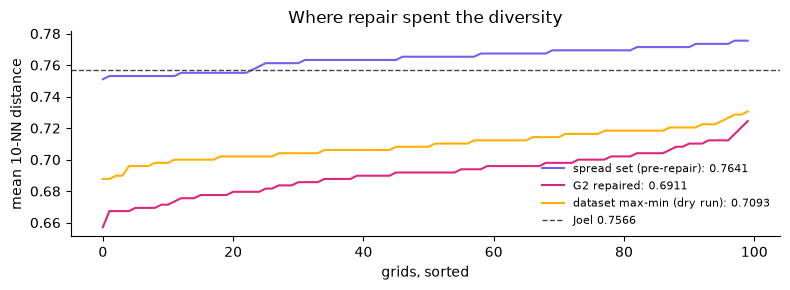

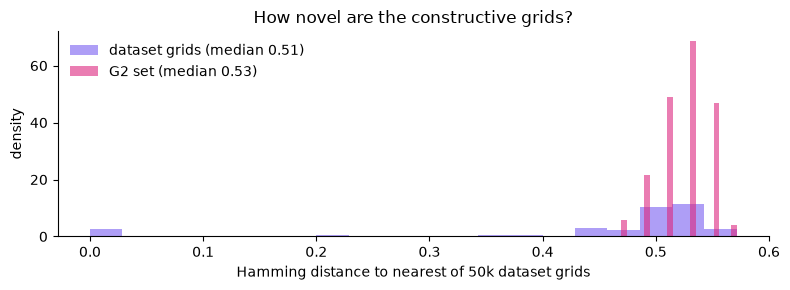

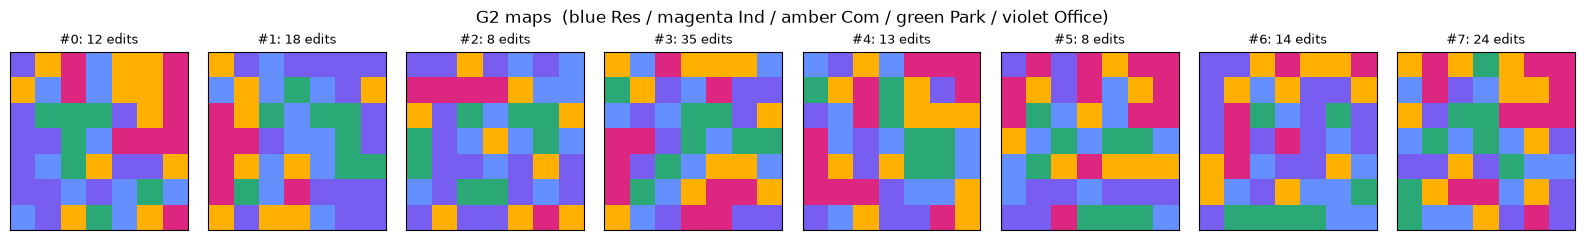

G2 diversity 0.6911 vs Joel 0.7566 (gap +0.0655) | repair cost 0.0730 diversity


In [29]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# 1 - per-advisor predicted margins above the cutoffs
fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ai, adv in enumerate(ADVISOR_NAMES):
    ax = axes[ai]
    m = g2_pred[:, ai] - CUTS[ai]
    ax.hist(m, bins=25, color="#648FFF")
    ax.axvline(REPAIR_MARGIN, color="#DC267F", linestyle="--", label=f"bar (+{REPAIR_MARGIN:g})")
    ax.axvline(0, color="#444444", linewidth=1, label="cutoff")
    ax.set_title(f"{adv}  (min {m.min():+.3f})")
    ax.set_xlabel("predicted − cutoff")
    ax.spines[["right", "top"]].set_visible(False)
axes[0].set_ylabel("grids")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("G2 set: predicted margin above each advisor's cutoff")
plt.tight_layout()
plt.show()

# 2 - off-distribution check: ensemble disagreement vs dataset grids
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(sample_spread.max(axis=1), bins=60, density=True, alpha=0.6,
        color="#785EF0", label="dataset sample (20k)")
ax.hist(g2_spread.max(axis=1), bins=20, density=True, alpha=0.6,
        color="#DC267F", label="G2 constructive set (100)")
ax.set_xlabel("max ensemble spread across advisors")
ax.set_ylabel("density")
ax.set_title("Do the models disagree more on our constructive grids?")
ax.legend(frameon=False)
ax.spines[["right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()


# 3 - diversity anatomy: per-grid mean 10-NN distance (the score is this curve's mean)
def mean10_per_grid(gset):
    D = dist_matrix(flat_of(gset))
    np.fill_diagonal(D, np.inf)
    return np.sort(np.partition(D, 10, axis=1)[:, :10].mean(axis=1))


fig, ax = plt.subplots(figsize=(8, 3))
for gset, label, color in [(SPREAD_SET, "spread set (pre-repair)", "#785EF0"),
                           (G2_SET, "G2 repaired", "#DC267F"),
                           (dry, "dataset max-min (dry run)", "#FFB000")]:
    v = mean10_per_grid(gset)
    ax.plot(v, color=color, label=f"{label}: {v.mean():.4f}")
ax.axhline(0.7566, color="#444444", linewidth=1, linestyle="--", label="Joel 0.7566")
ax.set_xlabel("grids, sorted")
ax.set_ylabel("mean 10-NN distance")
ax.set_title("Where repair spent the diversity")
ax.legend(frameon=False, fontsize=8)
ax.spines[["right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()

# 4 - novelty: nearest-dataset-grid distance (50k reference sample)
_r = np.random.default_rng(7)
ref = flat_of(grids[_r.choice(len(grids), 50_000, replace=False)])


def nearest_ref_dist(gset):
    return np.array([(ref != f[None, :]).mean(axis=1).min() for f in flat_of(gset)])


nn_g2 = nearest_ref_dist(G2_SET)
nn_ds = nearest_ref_dist(grids[_r.choice(len(grids), 100, replace=False)])
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(nn_ds, bins=20, density=True, alpha=0.6, color="#785EF0",
        label=f"dataset grids (median {np.median(nn_ds):.2f})")
ax.hist(nn_g2, bins=20, density=True, alpha=0.6, color="#DC267F",
        label=f"G2 set (median {np.median(nn_g2):.2f})")
ax.set_xlabel("Hamming distance to nearest of 50k dataset grids")
ax.set_ylabel("density")
ax.set_title("How novel are the constructive grids?")
ax.legend(frameon=False)
ax.spines[["right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()

# 5 - gallery: first 8 repaired maps (0 Res, 1 Ind, 2 Com, 3 Park, 4 Office)
district_colors = ["#648FFF", "#DC267F", "#FFB000", "#2AA876", "#785EF0"]
cmap = ListedColormap(district_colors)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for k, ax in enumerate(axes):
    ax.imshow(G2_SET[k], cmap=cmap, vmin=0, vmax=4)
    ax.set_title(f"#{k}: {g2_stats['edits'][k]} edits", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("G2 maps  (blue Res / magenta Ind / amber Com / green Park / violet Office)")
plt.tight_layout()
plt.show()

print(f"G2 diversity {diversity_score(G2_SET):.4f} vs Joel 0.7566 "
      f"(gap {0.7566 - diversity_score(G2_SET):+.4f}) | repair cost "
      f"{diversity_score(SPREAD_SET) - diversity_score(G2_SET):.4f} diversity")


## G2 verdict

*(Fill in after the run: diversity retained after repair, edit counts, and whether the repaired
set beats 0.7566 on raw diversity. If it does and all grids clear the bar: **Try #1** =
`save_submission(G2_SET.astype(np.int64))` and upload the `.npy`. The scoreboard result then
calibrates the margin for G3.)*

Next batch: **G3** (set-level soft anneal from `G2_SET`) and **G4** (Monte-Carlo expected score).


# Phase G3 — Joint soft optimization over the whole set

Take the repaired set and nudge single cells across all 100 maps at once, chasing one combined
objective: `diversity − λ(t) · total_shortfall_below_bar`. λ starts tiny (maps may dip below
the bar early, letting the search cross "almost valid" territory instead of walking around it)
and rises geometrically until violations are effectively forbidden; temperature falls so the
search settles. A final repair pass fixes any stragglers.

*The soft-penalty idea matches Joel's `anneal.py` (his 0.7566 likely comes from it); what's ours
is the starting point — his soft runs begin from validity-born pools, ours from the constructive
G2 set — and the optional per-grid `kappa` bar.*

**Cost control:** the models are called lazily — a proposal is rated only if it could still be
accepted even when fixing the grid's entire shortfall. Everything else is rejected on cheap
numpy diversity math alone. Dials: `steps` (50k ≈ a few min for a quick look; 500k+ for a real
run), `kappa` (per-grid uncertainty bar; figure 2 says 0.0 is fine today).


In [52]:
def joint_anneal(grid_set, steps=500_000, margin=0.06, kappa=0.0,
                 lam0=3e-3, lam1=3.0, T0=5e-5, T1=1e-6, seed=0, report=50_000):
    """Set-level soft anneal: maximize fast_score - lam(t) * shortfall below the bar.

    Metropolis on single-cell proposals; lam rises geometrically (soft -> effectively hard),
    T falls geometrically. Lazy rating: a proposal that cannot be accepted even if its grid's
    whole shortfall vanished is rejected without calling the models."""
    g = np.asarray(grid_set).copy()
    n = len(g)
    flat = g.reshape(n, -1)  # view: edits via flat update g too
    D = dist_matrix(flat)
    score = fast_score(D)
    pred, spread = rate(g)
    sf = total_shortfall(pred, bar(margin, spread, kappa))
    r = np.random.default_rng(seed)
    lam = lam0 * (lam1 / lam0) ** (np.arange(steps) / steps)
    T = T0 * (T1 / T0) ** (np.arange(steps) / steps)
    rated = accepted = 0
    history = []
    t0 = time.time()
    for t in range(steps):
        i, c, v = int(r.integers(n)), int(r.integers(49)), int(r.integers(5))
        if v == flat[i, c]:
            continue
        row = row_after_change(flat, D, i, c, v)
        D2 = D.copy()
        D2[i], D2[:, i] = row, row
        new_score = fast_score(D2)
        d_gain = new_score - score
        tlogu = T[t] * np.log(r.random() + 1e-300)
        if d_gain + lam[t] * sf[i] < tlogu:
            continue  # hopeless even if the move fixed grid i's whole shortfall
        old = flat[i, c]
        flat[i, c] = v          # flat is a view of g, so rate() sees the mutated grid
        p1, s1 = rate(g[i:i + 1])
        flat[i, c] = old
        rated += 1
        sf_new = total_shortfall(p1, bar(margin, s1, kappa))[0]
        if d_gain - lam[t] * (sf_new - sf[i]) >= tlogu:
            flat[i, c] = v
            D, score = D2, new_score
            pred[i], spread[i] = p1[0], s1[0]
            sf[i] = sf_new
            accepted += 1
        if report and (t + 1) % report == 0:
            below = int((sf > 0).sum())
            history.append((t + 1, score, below))
            print(f"  step {t + 1:>9,}: diversity {score:.4f}, below bar {below:>3}, "
                  f"rated {rated:,}, accepted {accepted:,}, lam {lam[t]:.2g}, "
                  f"{time.time() - t0:.0f}s")
    return g, {"history": history, "rated": rated, "accepted": accepted,
               "final_below": int((sf > 0).sum())}


In [31]:
G3_STEPS = 500_000  # quick look: 50_000; serious run: 500_000+

t0 = time.time()
G3_RAW, g3_info = joint_anneal(G2_SET, steps=G3_STEPS, margin=REPAIR_MARGIN, kappa=0.0)
print(f"\nanneal took {time.time() - t0:.0f}s | rated {g3_info['rated']:,} of "
      f"{G3_STEPS:,} proposals | still below bar: {g3_info['final_below']}")

# Straggler pass: grids already above the bar skip instantly, so this is cheap.
G3_SET, _ = repair_set(G3_RAW, margin=REPAIR_MARGIN, beta=BETA, report_every=0)
g3_pred, g3_spread = rate(G3_SET)
print(f"all clear bar at margin {REPAIR_MARGIN}: "
      f"{approve(g3_pred, margin=REPAIR_MARGIN).all()}"
      f"   (worst margin above cuts: {(g3_pred - CUTS).min():.3f})")
print(f"diversity: G2 {diversity_score(G2_SET):.4f} -> G3 {diversity_score(G3_SET):.4f}"
      f"   (spread set was {diversity_score(SPREAD_SET):.4f}; Joel 0.7566)")

save_candidate(G3_SET.astype(np.int64), f"g3_annealed_m{REPAIR_MARGIN:g}")


  step    50,000: diversity 0.7245, below bar  84, rated 32,067, accepted 2,979, lam 0.006, 117s
  step   200,000: diversity 0.7296, below bar  37, rated 95,085, accepted 4,774, lam 0.048, 336s
  step   250,000: diversity 0.7295, below bar  32, rated 110,345, accepted 4,896, lam 0.095, 390s
  step   300,000: diversity 0.7305, below bar  27, rated 124,628, accepted 4,991, lam 0.19, 442s
  step   450,000: diversity 0.7309, below bar  21, rated 165,377, accepted 5,146, lam 1.5, 587s

anneal took 635s | rated 179,036 of 500,000 proposals | still below bar: 19
all clear bar at margin 0.06: True   (worst margin above cuts: 0.060)
diversity: G2 0.6911 -> G3 0.7250   (spread set was 0.7641; Joel 0.7566)
saved candidate /Users/fb/repos/2.156-ps2/data/candidates/g3_annealed_m0.06.npy  (diversity 0.7250)


'/Users/fb/repos/2.156-ps2/data/candidates/g3_annealed_m0.06.npy'

## G3 diagnostics — same views as G2, overlaid

Same reads as the G2 diagnostics, now comparing before/after the joint anneal:
the anneal **trajectory** (did diversity climb? did below-bar return to 0 as λ tightened?),
**margins** (did grids keep slack above the bar or hug it again?), the **off-distribution
check** for the annealed maps, the **10-NN curves** (how much of the repair tax was recovered),
and the gallery.


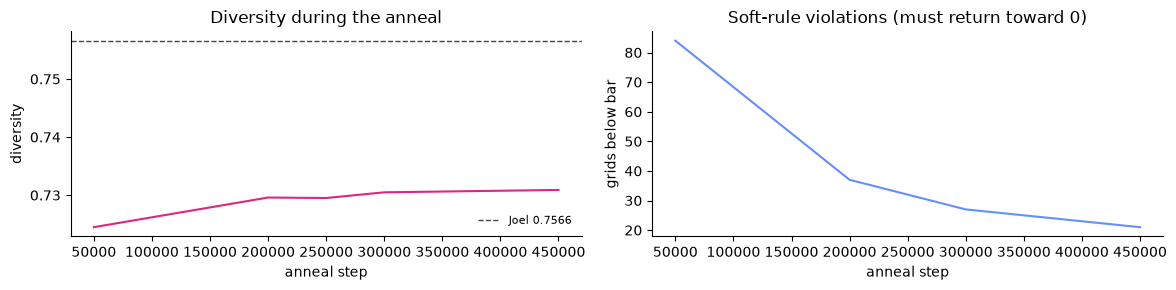

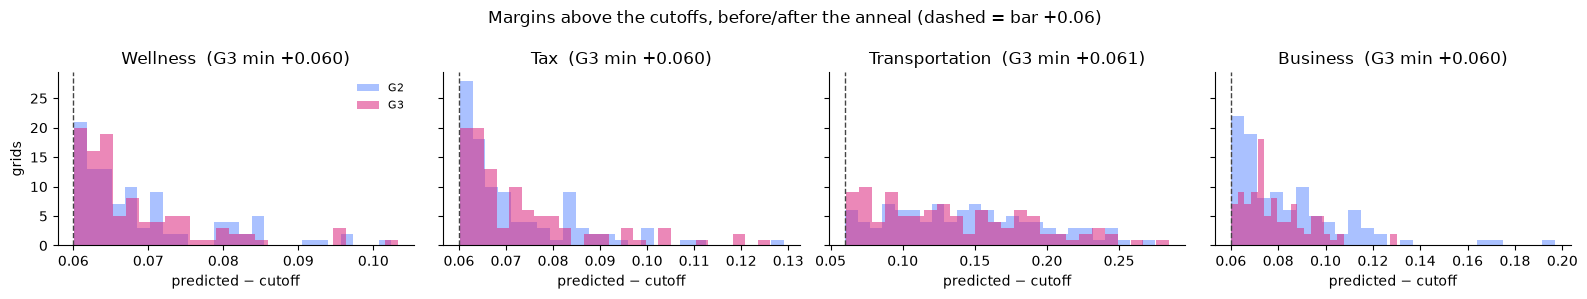

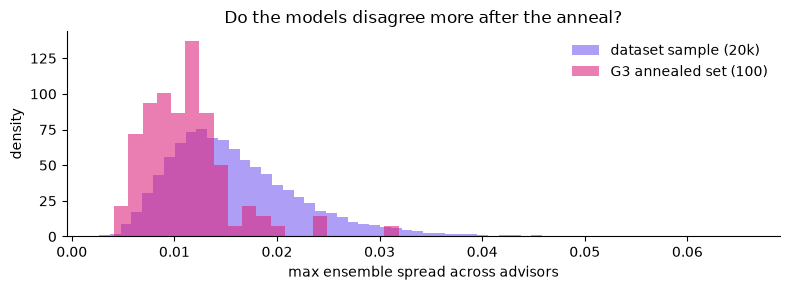

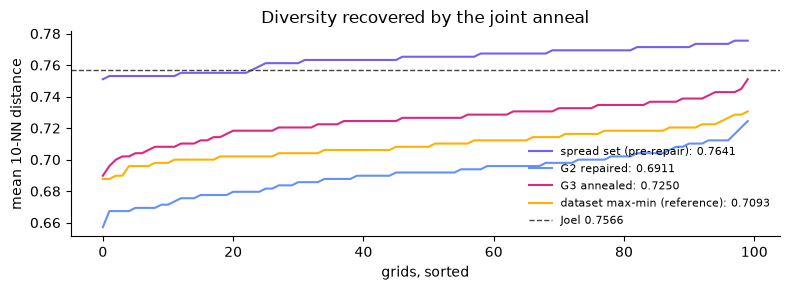

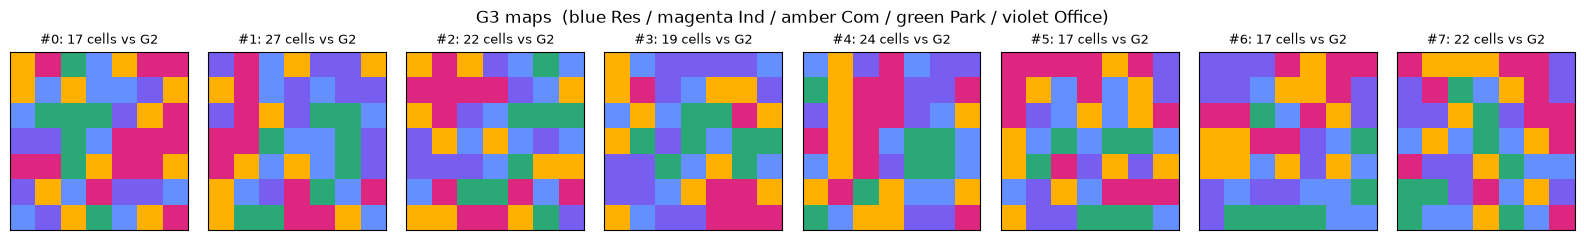

G3 diversity 0.7250 vs Joel 0.7566 (gap +0.0316) | anneal recovered +0.0339 of the 0.0730 repair tax | cells changed vs G2: 1891


In [32]:
# 0 - anneal trajectory
if g3_info["history"]:
    h = np.array(g3_info["history"])
    fig, axes = plt.subplots(1, 2, figsize=(12, 3))
    axes[0].plot(h[:, 0], h[:, 1], color="#DC267F")
    axes[0].axhline(0.7566, color="#444444", linewidth=1, linestyle="--", label="Joel 0.7566")
    axes[0].set_xlabel("anneal step")
    axes[0].set_ylabel("diversity")
    axes[0].set_title("Diversity during the anneal")
    axes[0].legend(frameon=False, fontsize=8)
    axes[1].plot(h[:, 0], h[:, 2], color="#648FFF")
    axes[1].set_xlabel("anneal step")
    axes[1].set_ylabel("grids below bar")
    axes[1].set_title("Soft-rule violations (must return toward 0)")
    for ax in axes:
        ax.spines[["right", "top"]].set_visible(False)
    plt.tight_layout()
    plt.show()

# 1 - margins per advisor: G2 vs G3
fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ai, adv in enumerate(ADVISOR_NAMES):
    ax = axes[ai]
    ax.hist(g2_pred[:, ai] - CUTS[ai], bins=25, alpha=0.55, color="#648FFF", label="G2")
    ax.hist(g3_pred[:, ai] - CUTS[ai], bins=25, alpha=0.55, color="#DC267F", label="G3")
    ax.axvline(REPAIR_MARGIN, color="#444444", linestyle="--", linewidth=1)
    ax.set_title(f"{adv}  (G3 min {(g3_pred[:, ai] - CUTS[ai]).min():+.3f})")
    ax.set_xlabel("predicted − cutoff")
    ax.spines[["right", "top"]].set_visible(False)
axes[0].set_ylabel("grids")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle(f"Margins above the cutoffs, before/after the anneal (dashed = bar +{REPAIR_MARGIN:g})")
plt.tight_layout()
plt.show()

# 2 - off-distribution check for the annealed set
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(sample_spread.max(axis=1), bins=60, density=True, alpha=0.6,
        color="#785EF0", label="dataset sample (20k)")
ax.hist(g3_spread.max(axis=1), bins=20, density=True, alpha=0.6,
        color="#DC267F", label="G3 annealed set (100)")
ax.set_xlabel("max ensemble spread across advisors")
ax.set_ylabel("density")
ax.set_title("Do the models disagree more after the anneal?")
ax.legend(frameon=False)
ax.spines[["right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()

# 3 - 10-NN curves: how much of the repair tax did the anneal recover?
fig, ax = plt.subplots(figsize=(8, 3))
for gset, label, color in [(SPREAD_SET, "spread set (pre-repair)", "#785EF0"),
                           (G2_SET, "G2 repaired", "#648FFF"),
                           (G3_SET, "G3 annealed", "#DC267F"),
                           (dry, "dataset max-min (reference)", "#FFB000")]:
    v = mean10_per_grid(gset)
    ax.plot(v, color=color, label=f"{label}: {v.mean():.4f}")
ax.axhline(0.7566, color="#444444", linewidth=1, linestyle="--", label="Joel 0.7566")
ax.set_xlabel("grids, sorted")
ax.set_ylabel("mean 10-NN distance")
ax.set_title("Diversity recovered by the joint anneal")
ax.legend(frameon=False, fontsize=8)
ax.spines[["right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()

# 4 - gallery: first 8 annealed maps
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for k, ax in enumerate(axes):
    ax.imshow(G3_SET[k], cmap=cmap, vmin=0, vmax=4)
    changed = int((G3_SET[k] != G2_SET[k]).sum())
    ax.set_title(f"#{k}: {changed} cells vs G2", fontsize=9)
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("G3 maps  (blue Res / magenta Ind / amber Com / green Park / violet Office)")
plt.tight_layout()
plt.show()

print(f"G3 diversity {diversity_score(G3_SET):.4f} vs Joel 0.7566 "
      f"(gap {0.7566 - diversity_score(G3_SET):+.4f}) | anneal recovered "
      f"{diversity_score(G3_SET) - diversity_score(G2_SET):+.4f} of the "
      f"{diversity_score(SPREAD_SET) - diversity_score(G2_SET):.4f} repair tax | "
      f"cells changed vs G2: {(G3_SET != G2_SET).sum()}")


# Phase G4 — Expected score: simulate the scoreboard before spending a try

Raw diversity assumes all 100 grids pass. The scoreboard deletes failures first. So: calibrate
**P(truly valid | predicted score)** per advisor from an honest OOF pass (binned empirical pass
rates, forced monotone), multiply the four probabilities per grid (independence assumption —
the labeled subsets are disjoint, so joint validity is never observed; same assumption Joel
makes), then Monte-Carlo the deletion process and score the survivors with the course metric.

**Candidates are chosen by expected score, not raw diversity.** Caveat to keep in mind: the
calibration curves come from dataset grids; figure 2 (ensemble spread) says our constructive
grids look in-distribution to the models, but the scoreboard tries are the real calibration.


In [53]:
def _oof_pass_curve(advisor_idx, n_bins=40, min_bin=20):
    """Empirical P(y >= 0.75 | predicted) for one advisor, from 5-fold OOF predictions,
    binned by prediction quantiles and forced monotone (cummax)."""
    adv = ADVISOR_NAMES[advisor_idx]
    g_sub, y = select_rated_subset(grids, ratings[:, advisor_idx])
    X = featurize(g_sub)[FEATURE_OF[adv]]
    oof = np.empty(len(y))
    for tr, te in KFold(5, shuffle=True, random_state=0).split(X):
        oof[te] = make_model(adv).fit(X[tr], y[tr]).predict(X[te])
    n_bins = max(2, min(n_bins, len(y) // (2 * min_bin)))  # keep every bin populated
    edges = np.quantile(oof, np.linspace(0, 1, n_bins + 1))
    mids, rates = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (oof >= lo) & (oof <= hi)
        if m.sum() >= min_bin:
            mids.append(oof[m].mean())
            rates.append((y[m] >= VALID_THRESHOLD).mean())
    mids = np.array(mids)
    rates = np.maximum.accumulate(np.array(rates))
    return lambda p: np.interp(p, mids, rates)


t0 = time.time()
PASS_CURVES = [_oof_pass_curve(ai) for ai in range(4)]
print(f"calibration curves fit in {time.time() - t0:.0f}s")


def pass_prob(pred):
    """(n,4) predictions -> (n,) P(all four advisors truly >= 0.75)."""
    per = np.stack([PASS_CURVES[ai](pred[:, ai]) for ai in range(4)], axis=1)
    return per.prod(axis=1)


def expected_score(grid_set, draws=500, seed=0):
    """Monte-Carlo scoreboard: grids survive with their calibrated pass probability,
    failures are deleted, survivors scored by the course metric (which divides by 100
    regardless of survivor count). Returns (mean, std, P(all pass))."""
    gs = np.asarray(grid_set)
    p = pass_prob(rate(gs)[0])
    r = np.random.default_rng(seed)
    scores = []
    for _ in range(draws):
        mask = r.random(len(gs)) < p
        scores.append(diversity_score(gs[mask]) if mask.sum() >= 2 else 0.0)
    return float(np.mean(scores)), float(np.std(scores)), float(np.prod(p))


calibration curves fit in 42s


## G4 diagnostics

Left: the calibration curves the expected score stands on — steepness around the cutoff says
what each 0.01 of margin buys in real pass probability. Right after: the simulated scoreboard
outcomes for each candidate — the mean is the table's number, the left tail is the risk you
accept by submitting.


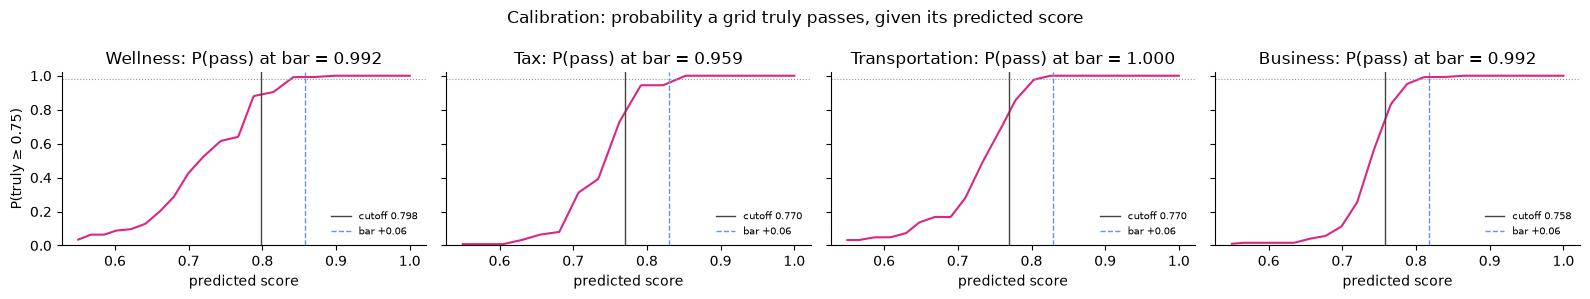

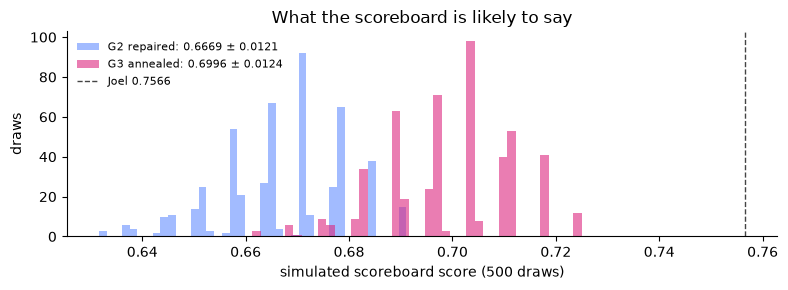

In [34]:
# 1 - per-advisor calibration curves
fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
px = np.linspace(0.55, 1.0, 300)
for ai, adv in enumerate(ADVISOR_NAMES):
    ax = axes[ai]
    ax.plot(px, PASS_CURVES[ai](px), color="#DC267F")
    ax.axvline(CUTS[ai], color="#444444", linewidth=1, label=f"cutoff {CUTS[ai]:.3f}")
    ax.axvline(CUTS[ai] + REPAIR_MARGIN, color="#648FFF", linewidth=1, linestyle="--",
               label=f"bar +{REPAIR_MARGIN:g}")
    ax.axhline(0.98, color="#999999", linewidth=0.8, linestyle=":")
    ax.set_title(f"{adv}: P(pass) at bar = {float(PASS_CURVES[ai](CUTS[ai] + REPAIR_MARGIN)):.3f}")
    ax.set_xlabel("predicted score")
    ax.set_ylim(0, 1.02)
    ax.legend(frameon=False, fontsize=7)
    ax.spines[["right", "top"]].set_visible(False)
axes[0].set_ylabel("P(truly ≥ 0.75)")
fig.suptitle("Calibration: probability a grid truly passes, given its predicted score")
plt.tight_layout()
plt.show()

# 2 - simulated scoreboard outcomes per candidate
fig, ax = plt.subplots(figsize=(8, 3))
for cand, label, color in [(G2_SET, "G2 repaired", "#648FFF"),
                           (G3_SET, "G3 annealed", "#DC267F")]:
    gs = np.asarray(cand)
    p = pass_prob(rate(gs)[0])
    r = np.random.default_rng(0)
    sims = [diversity_score(gs[r.random(len(gs)) < p]) for _ in range(500)]
    ax.hist(sims, bins=40, alpha=0.6, color=color,
            label=f"{label}: {np.mean(sims):.4f} ± {np.std(sims):.4f}")
ax.axvline(0.7566, color="#444444", linewidth=1, linestyle="--", label="Joel 0.7566")
ax.set_xlabel("simulated scoreboard score (500 draws)")
ax.set_ylabel("draws")
ax.set_title("What the scoreboard is likely to say")
ax.legend(frameon=False, fontsize=8)
ax.spines[["right", "top"]].set_visible(False)
plt.tight_layout()
plt.show()


In [35]:
rows = []
for name, cand in [("G2 repaired", G2_SET),
                   ("G3 annealed", G3_SET),
                   ("dataset max-min (reference)", dry)]:
    mu, sd, p_all = expected_score(cand)
    pr, _ = rate(np.asarray(cand))
    rows.append({"candidate": name,
                 "diversity if all pass": round(diversity_score(np.asarray(cand)), 4),
                 "expected score": round(mu, 4),
                 "+/-": round(sd, 4),
                 "P(all 100 pass)": round(p_all, 3),
                 "worst margin above cuts": round(float((pr - CUTS).min()), 3)})
pd.DataFrame(rows).set_index("candidate")


,diversity if all pass,expected score,+/-,P(all 100 pass),worst margin above cuts
candidate,,,,,
G2 repaired,0.6911,0.6669,0.0121,0.026,0.060
G3 annealed,0.7250,0.6996,0.0124,0.025,0.060
dataset max-min (reference),0.7093,0.0318,0.0119,0.000,-0.212


## Experiment ledger — every run gets logged

`log_run(name, grid_set, config, ...)` computes all gate-dependent metrics **now** (with the
live models, recorded MC seed/draws), saves the grids to `experiments/sets/<name>.npy`, and
appends one JSON line to `experiments/runs.jsonl`. The dashboard notebook
(`experiments_dashboard.ipynb`) only *reads* those files — it never retrains or re-estimates
anything, so what it shows is exactly what the run measured. `experiments/` is git-tracked:
each record carries the repo commit, so every number is traceable to code.

After a real scoreboard try: `log_scoreboard(name, actual)` writes the true score into the
run's record — the actual-vs-expected comparison is the calibration evidence for margin calls.


In [54]:
import json as _json
import subprocess
from datetime import datetime

EXP_DIR = os.path.join(PS2_ROOT, "experiments")
SETS_DIR = os.path.join(EXP_DIR, "sets")
LEDGER = os.path.join(EXP_DIR, "runs.jsonl")
os.makedirs(SETS_DIR, exist_ok=True)


def _git_state():
    try:
        h = subprocess.run(["git", "-C", PS2_ROOT, "rev-parse", "--short", "HEAD"],
                           capture_output=True, text=True).stdout.strip()
        dirty = subprocess.run(["git", "-C", PS2_ROOT, "status", "--porcelain"],
                               capture_output=True, text=True).stdout.strip() != ""
        return h + ("+dirty" if dirty else "")
    except Exception:
        return "unknown"


def _ledger_records():
    if not os.path.exists(LEDGER):
        return []
    with open(LEDGER) as f:
        return [_json.loads(line) for line in f if line.strip()]


def log_run(name, grid_set, config, parent=None, note="", draws=500, mc_seed=0):
    """Log one experiment: metrics computed NOW through the live gate; grids saved;
    one JSON line appended. The dashboard only reads - it recomputes nothing."""
    assert all(r["name"] != name for r in _ledger_records()), f"run {name!r} already logged"
    gs = np.asarray(grid_set).astype(np.int64)
    assert gs.shape == (100, 7, 7) and gs.min() >= 0 and gs.max() <= 4
    pred, spread = rate(gs)
    p = pass_prob(pred)
    mu, sd, p_all = expected_score(gs, draws=draws, seed=mc_seed)
    rec = {
        "name": name,
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "commit": _git_state(),
        "parent": parent,
        "note": note,
        "config": config,
        "diversity": round(float(diversity_score(gs)), 6),
        "expected_score": round(mu, 6),
        "expected_sd": round(sd, 6),
        "p_all_pass": round(p_all, 6),
        "mc_draws": draws,
        "mc_seed": mc_seed,
        "worst_margin": round(float((pred - CUTS).min()), 6),
        "min_margin_per_advisor": {a: round(float((pred[:, i] - CUTS[i]).min()), 6)
                                   for i, a in enumerate(ADVISOR_NAMES)},
        "mean_pass_prob": round(float(p.mean()), 6),
        "max_ensemble_spread": round(float(spread.max()), 6),
        "set_file": os.path.relpath(os.path.join(SETS_DIR, f"{name}.npy"), PS2_ROOT),
        "scoreboard": None,
    }
    np.save(os.path.join(SETS_DIR, f"{name}.npy"), gs)
    with open(LEDGER, "a") as f:
        f.write(_json.dumps(rec) + "\n")
    print(f"logged {name}: diversity {rec['diversity']:.4f}, expected {mu:.4f} +/- {sd:.4f}, "
          f"P(all pass) {p_all:.3f}")
    return rec


def log_scoreboard(name, actual_score, note=""):
    """Record the real scoreboard result for a logged run (rewrites its line in place)."""
    recs = _ledger_records()
    hit = [r for r in recs if r["name"] == name]
    assert hit, f"no run named {name!r}"
    hit[0]["scoreboard"] = float(actual_score)
    if note:
        hit[0]["scoreboard_note"] = note
    with open(LEDGER, "w") as f:
        for r in recs:
            f.write(_json.dumps(r) + "\n")
    print(f"{name}: scoreboard {actual_score:.4f} vs expected {hit[0]['expected_score']:.4f} "
          f"({actual_score - hit[0]['expected_score']:+.4f}) "
          f"vs raw diversity {hit[0]['diversity']:.4f}")


def runs_table():
    recs = _ledger_records()
    if not recs:
        return pd.DataFrame()
    return pd.json_normalize(recs).sort_values(
        "expected_score", ascending=False).set_index("name")


In [55]:
# Retro-log today's two completed runs (executed outputs are in commit f235344). Metrics are
# recomputed from the saved candidate grids through the SAME frozen gate and seeds, so they
# reproduce the printed numbers exactly - a determinism check, not an estimate.
for name, path, cfg, parent, note in [
    ("g2_spread200k_b01_m06", "data/candidates/g2_repaired_m0.06.npy",
     {"margin": 0.06, "kappa": 0.0, "beta": 0.1, "spread_steps": 200_000,
      "spread_seed": 1, "repair_seed": 0}, None,
     "first full run; printed: diversity 0.6911, expected 0.6669"),
    ("g3_anneal500k_m06", "data/candidates/g3_annealed_m0.06.npy",
     {"margin": 0.06, "kappa": 0.0, "beta": 0.1, "anneal_steps": 500_000,
      "lam0": 3e-3, "lam1": 3.0, "anneal_seed": 0}, "g2_spread200k_b01_m06",
     "first full run; printed: diversity 0.7250, expected 0.6996; anneal plateaued ~50k"),
]:
    if any(r["name"] == name for r in _ledger_records()):
        print(f"{name} already logged; skipping")
    else:
        log_run(name, np.load(os.path.join(PS2_ROOT, path)), cfg, parent=parent, note=note)

runs_table()[["diversity", "expected_score", "p_all_pass", "worst_margin", "scoreboard"]]


g2_spread200k_b01_m06 already logged; skipping
g3_anneal500k_m06 already logged; skipping


,diversity,expected_score,p_all_pass,worst_margin,scoreboard
name,,,,,
e2_sp2M_b03_m06_g3,0.725041,0.699749,0.025108,0.060008,None
g3_anneal500k_m06,0.724980,0.699561,0.025210,0.060066,None
e2_sp2M_b03_m06_safe0.1,0.685224,0.685078,0.977424,0.100044,None
e2_sp2M_b03_m06_g2,0.695122,0.671777,0.028465,0.060089,None
g2_spread200k_b01_m06,0.691061,0.666879,0.026154,0.060062,None


## Experiment driver — one call per experiment, every stage logged

`run_pipeline(tag, ...)` chains spread → repair → joint anneal (→ optional safety pass) with
one config, logging each stage to the ledger with parent links (`<tag>_g2`, `<tag>_g3`,
`<tag>_safe<m>`). The cells above remain the documented first run; experiments from here are
one-liners, and the dashboard compares them all.

**Experiment e2** (the improvements chosen from the first run's diagnostics):
- spread anneal 200k → **2M steps** (it was still climbing at 200k; starts the chain ~0.78
  instead of 0.764);
- repair β 0.1 → **0.3** (defend diversity harder during repair);
- a **safety variant** of the final set re-repaired at margin 0.10 — trades a little diversity
  for fewer expected casualties; the expected-score column arbitrates whether it wins.


In [56]:
def run_pipeline(tag, spread_steps=2_000_000, spread_seed=1, beta=0.3, margin=0.06,
                 kappa=0.0, anneal_steps=500_000, anneal_seed=0, safety_margin=None,
                 n=100, log=True):
    """One experiment = one call: spread -> repair -> joint anneal (-> safety pass).
    Each stage is logged to the ledger with full config and parent links."""
    cfg = dict(spread_steps=spread_steps, spread_seed=spread_seed, beta=beta, margin=margin,
               kappa=kappa, anneal_steps=anneal_steps, anneal_seed=anneal_seed)
    t0 = time.time()
    S = np.random.default_rng(spread_seed).integers(0, 5, (n, 7, 7))
    S, _ = spread_anneal(S, steps=spread_steps, seed=spread_seed,
                         report=max(spread_steps // 4, 1))
    sdiv = diversity_score(S)
    print(f"[{tag}] spread set: {sdiv:.4f}  ({time.time() - t0:.0f}s)")

    G2x, st = repair_set(S, margin=margin, kappa=kappa, beta=beta, report_every=0)
    print(f"[{tag}] repaired:   {diversity_score(G2x):.4f}  (edits {st['edits'].sum()}, "
          f"unrepaired {st['unrepaired']}, {time.time() - t0:.0f}s)")
    if log:
        log_run(f"{tag}_g2", G2x,
                {**cfg, "stage": "g2", "spread_diversity": round(float(sdiv), 6)},
                note="repair of the spread set")

    raw, info = joint_anneal(G2x, steps=anneal_steps, margin=margin, kappa=kappa,
                             seed=anneal_seed)
    G3x, _ = repair_set(raw, margin=margin, kappa=kappa, beta=beta, report_every=0)
    print(f"[{tag}] annealed:   {diversity_score(G3x):.4f}  ({time.time() - t0:.0f}s)")
    if log:
        log_run(f"{tag}_g3", G3x, {**cfg, "stage": "g3"}, parent=f"{tag}_g2",
                note="joint soft anneal + straggler repair")

    out = {"spread": S, "g2": G2x, "g3": G3x}
    if safety_margin is not None:
        SAFE, _ = repair_set(G3x, margin=safety_margin, kappa=kappa, beta=beta,
                             report_every=0)
        print(f"[{tag}] safety@{safety_margin:g}: {diversity_score(SAFE):.4f}  "
              f"({time.time() - t0:.0f}s)")
        if log:
            log_run(f"{tag}_safe{safety_margin:g}", SAFE,
                    {**cfg, "stage": "safety", "safety_margin": safety_margin},
                    parent=f"{tag}_g3",
                    note="post-anneal margin boost: fewer casualties for a little diversity")
        out["safe"] = SAFE
    return out


In [39]:
EXP2 = run_pipeline("e2_sp2M_b03_m06", spread_steps=2_000_000, beta=0.3, margin=0.06, safety_margin=0.10)

runs_table()[["diversity", "expected_score", "expected_sd", "p_all_pass",
              "worst_margin", "scoreboard"]]


  step 500,000: 0.7323
  step 1,000,000: 0.7561
  step 1,500,000: 0.7729
  step 2,000,000: 0.7736
[e2_sp2M_b03_m06] spread set: 0.7736  (64s)
[e2_sp2M_b03_m06] repaired:   0.6951  (edits 1726, unrepaired [], 108s)
logged e2_sp2M_b03_m06_g2: diversity 0.6951, expected 0.6718 +/- 0.0121, P(all pass) 0.028
  step   100,000: diversity 0.7265, below bar  64, rated 57,686, accepted 3,795, lam 0.012, 201s
  step   250,000: diversity 0.7294, below bar  33, rated 112,206, accepted 4,567, lam 0.095, 395s
[e2_sp2M_b03_m06] annealed:   0.7250  (754s)
logged e2_sp2M_b03_m06_g3: diversity 0.7250, expected 0.6997 +/- 0.0126, P(all pass) 0.025
[e2_sp2M_b03_m06] safety@0.1: 0.6852  (802s)
logged e2_sp2M_b03_m06_safe0.1: diversity 0.6852, expected 0.6851 +/- 0.0011, P(all pass) 0.977


,diversity,expected_score,expected_sd,p_all_pass,worst_margin,scoreboard
name,,,,,,
e2_sp2M_b03_m06_g3,0.725041,0.699749,0.012584,0.025108,0.060008,None
g3_anneal500k_m06,0.724980,0.699561,0.012358,0.025210,0.060066,None
e2_sp2M_b03_m06_safe0.1,0.685224,0.685078,0.001066,0.977424,0.100044,None
e2_sp2M_b03_m06_g2,0.695122,0.671777,0.012104,0.028465,0.060089,None
g2_spread200k_b01_m06,0.691061,0.666879,0.012143,0.026154,0.060062,None


## G3 v2 — a real anneal: hot temperature + teleport moves

Diagnosis of the 0.725 attractor: v1's T0 = 5e-5 is ~20x smaller than a typical single-cell
diversity delta (~1e-3), so it rejected almost every downhill move from step one — a greedy
hill-climb wearing an annealer's clothes, and greedy is exactly what plateaus (Joel: greedy
spreading ~0.748–0.755; true annealing 0.774 unconstrained). v2 changes:

- **T0 = 1e-3** (matched to move size): genuine exploration early, geometric cooling as before;
- **teleports** every 25k steps: the most crowded grid is replaced by the farthest of 256 random
  candidates, repaired in place; kept only if the set score improves — an escape hatch no amount
  of single-cell wiggling provides;
- **best-valid snapshot**: a hot search wanders, so we return the best state where every grid
  cleared the bar, not the final state;
- **`rate_fast`** (the seed-0 refit only, 4 predictions instead of 12) inside the loop; the full
  ensemble still does final checks and logging. kappa is not supported here (it's been 0 all day).


In [59]:
def rate_fast(grid_arr):
    """Single-refit predictions for the anneal's inner loop (~3x fewer model calls).
    Full-ensemble rate() remains the authority for final checks and logging."""
    F = featurize(np.asarray(grid_arr))
    pred = np.empty((len(grid_arr), 4))
    for ai, adv in enumerate(ADVISOR_NAMES):
        pred[:, ai] = ENSEMBLES[adv][0].predict(F[FEATURE_OF[adv]])
    return pred


def _repair_grid(g, flat, D, pred, i, b, beta, rng, max_steps=300):
    """Diversity-aware repair of grid i in place (rate_fast). True if it clears b."""
    for _ in range(max_steps):
        sf_i = float(np.maximum(0, b - pred[i]).sum())
        if sf_i <= 0:
            return True
        variants, cells, vals = one_cell_variants(g[i])
        vp = rate_fast(variants)
        sf = np.maximum(0, b[None, :] - vp).sum(axis=1)
        old_match = flat[:, cells] == flat[i, cells][None, :]
        new_match = flat[:, cells] == vals[None, :]
        rows_new = D[i][:, None] + (old_match.astype(float) - new_match) / flat.shape[1]
        rows_new[i, :] = np.inf
        mean10_new = np.sort(rows_new, axis=0)[:10].mean(axis=0)
        row_cur = D[i].copy()
        row_cur[i] = np.inf
        objective = (sf_i - sf) + beta * (mean10_new - np.sort(row_cur)[:10].mean())
        qualify = sf < sf_i - 1e-12
        if not qualify.any():
            for c in rng.choice(49, 3, replace=False):
                flat[i, c] = rng.integers(5)
            row = (flat != flat[i]).mean(axis=1)
            row[i] = 0.0
            D[i], D[:, i] = row, row
            pred[i] = rate_fast(g[i:i + 1])[0]
            continue
        k = int(np.argmax(np.where(qualify, objective, -np.inf)))
        flat[i, cells[k]] = vals[k]
        row = rows_new[:, k].copy()
        row[i] = 0.0
        D[i], D[:, i] = row, row
        pred[i] = vp[k]
    return False


def joint_anneal2(grid_set, steps=1_000_000, margin=0.06, T0=1e-3, T1=1e-6,
                  lam0=3e-3, lam1=3.0, teleport_every=25_000, beta=0.3, seed=0,
                  report=100_000):
    """v2 anneal: exploration-capable temperature + periodic teleports of the most
    crowded grid. Returns the best fully-valid snapshot seen (rate_fast validity)."""
    g = np.asarray(grid_set).copy()
    n = len(g)
    flat = g.reshape(n, -1)
    D = dist_matrix(flat)
    score = fast_score(D)
    b = CUTS + margin
    pred = rate_fast(g)
    sf = np.maximum(0, b[None, :] - pred).sum(axis=1)
    r = np.random.default_rng(seed)
    lam = lam0 * (lam1 / lam0) ** (np.arange(steps) / steps)
    T = T0 * (T1 / T0) ** (np.arange(steps) / steps)
    rated = accepted = teleports = 0
    best_score, best_g = (score, g.copy()) if sf.max() <= 0 else (-np.inf, None)
    history = []
    t0 = time.time()
    for t in range(steps):
        if teleport_every and (t + 1) % teleport_every == 0:
            Dm = D.copy()
            np.fill_diagonal(Dm, np.inf)
            i = int(np.argmin(np.partition(Dm, 10, axis=1)[:, :10].mean(axis=1)))
            backup = (g[i].copy(), D[i].copy(), pred[i].copy(), score, float(sf[i]))
            cands = r.integers(0, 5, (256, 49))
            others = np.stack([flat[j] for j in range(n) if j != i])
            dmin = (cands[:, None, :] != others[None, :, :]).mean(axis=2).min(axis=1)
            flat[i] = cands[int(np.argmax(dmin))]
            row = (flat != flat[i]).mean(axis=1)
            row[i] = 0.0
            D[i], D[:, i] = row, row
            pred[i] = rate_fast(g[i:i + 1])[0]
            ok = _repair_grid(g, flat, D, pred, i, b, beta, r)
            new_score = fast_score(D)
            if ok and new_score > score:
                score = new_score
                sf[i] = 0.0
                teleports += 1
                if sf.max() <= 0 and score > best_score:
                    best_score, best_g = score, g.copy()
            else:
                flat[i] = backup[0].reshape(-1)
                D[i], D[:, i] = backup[1], backup[1]
                pred[i] = backup[2]
                score = backup[3]
                sf[i] = backup[4]
            continue
        i, c, v = int(r.integers(n)), int(r.integers(49)), int(r.integers(5))
        if v == flat[i, c]:
            continue
        row = row_after_change(flat, D, i, c, v)
        D2 = D.copy()
        D2[i], D2[:, i] = row, row
        new_score = fast_score(D2)
        d_gain = new_score - score
        tlogu = T[t] * np.log(r.random() + 1e-300)
        if d_gain + lam[t] * sf[i] < tlogu:
            continue
        old = flat[i, c]
        flat[i, c] = v
        p1 = rate_fast(g[i:i + 1])[0]
        flat[i, c] = old
        rated += 1
        sf_new = float(np.maximum(0, b - p1).sum())
        if d_gain - lam[t] * (sf_new - sf[i]) >= tlogu:
            flat[i, c] = v
            D, score = D2, new_score
            pred[i] = p1
            sf[i] = sf_new
            accepted += 1
            if sf.max() <= 0 and score > best_score:
                best_score, best_g = score, g.copy()
        if report and (t + 1) % report == 0:
            below = int((sf > 0).sum())
            history.append((t + 1, score, below))
            print(f"  step {t + 1:>9,}: diversity {score:.4f} "
                  f"(best valid {best_score:.4f}), below bar {below:>3}, "
                  f"rated {rated:,}, accepted {accepted:,}, teleports {teleports}, "
                  f"lam {lam[t]:.2g}, T {T[t]:.2g}, {time.time() - t0:.0f}s", flush=True)
    return (best_g if best_g is not None else g), {
        "history": history, "rated": rated, "accepted": accepted,
        "teleports": teleports, "best_valid_score": float(best_score)}


In [58]:
G3B_START = EXP2["g2"]  # the beta-0.3 repaired set from experiment e2

t0 = time.time()
G3B_RAW, g3b_info = joint_anneal2(G3B_START, steps=1_000_000, margin=0.06, teleport_every=25_000, beta=0.3)
print(f"\nanneal2 took {time.time() - t0:.0f}s | teleports {g3b_info['teleports']} | "
      f"best valid (rate_fast) {g3b_info['best_valid_score']:.4f}")

# full-ensemble authority: straggler repair + final check
G3B_SET, _ = repair_set(G3B_RAW, margin=0.06, beta=0.3, report_every=0)
g3b_pred, _ = rate(G3B_SET)
print(f"all clear bar: {approve(g3b_pred, margin=0.06).all()}   "
      f"diversity {diversity_score(G3B_SET):.4f}   (v1 attractor 0.7250; Joel 0.7566)")

log_run("e3_hotanneal1M_tp_m06", G3B_SET,
        {"margin": 0.06, "beta": 0.3, "anneal_steps": 1_000_000, "T0": 1e-3,
         "teleport_every": 25_000, "anneal_seed": 0, "engine": "joint_anneal2"},
        parent="e2_sp2M_b03_m06_g2",
        note="hot-T anneal + teleports; v1 plateaued at 0.725")
runs_table()[["diversity", "expected_score", "p_all_pass", "worst_margin", "scoreboard"]]



anneal2 took 673s | teleports 22 | best valid (rate_fast) -inf
all clear bar: True   diversity 0.7241   (v1 attractor 0.7250; Joel 0.7566)
logged e3_hotanneal1M_tp_m06: diversity 0.7241, expected 0.7021 +/- 0.0122, P(all pass) 0.043


,diversity,expected_score,p_all_pass,worst_margin,scoreboard
name,,,,,
e3_hotanneal1M_tp_m06,0.724061,0.702070,0.042548,0.060073,None
e2_sp2M_b03_m06_g3,0.725041,0.699749,0.025108,0.060008,None
g3_anneal500k_m06,0.724980,0.699561,0.025210,0.060066,None
e2_sp2M_b03_m06_safe0.1,0.685224,0.685078,0.977424,0.100044,None
e2_sp2M_b03_m06_g2,0.695122,0.671777,0.028465,0.060089,None
g2_spread200k_b01_m06,0.691061,0.666879,0.026154,0.060062,None


In [ ]:
sub = np.load(os.path.join(SETS_DIR, "e3_hotanneal1M_tp_m06.npy"))
save_submission(sub.astype(np.int64)) #/Users/fb/repos/2.156-ps2/submissions/submission_20261108_203200.npy

SAVED SUBMISSION /Users/fb/repos/2.156-ps2/submissions/submission_20261108_203200.npy


'/Users/fb/repos/2.156-ps2/submissions/submission_20261108_203200.npy'

In [61]:
log_scoreboard("e3_hotanneal1M_tp_m06", 0.71,
                note="try #1, 2026-11-08, submission_20261108_203200.npy")

e3_hotanneal1M_tp_m06: scoreboard 0.7100 vs expected 0.7021 (+0.0079) vs raw diversity 0.7241


## Submitting (manual, deliberate)

Pick the candidate with the best **expected score**, uncomment its line below, run, and upload
the saved **`.npy`** (never a json — that mistake cost Joel a try). Then log in `work_log.md`:
which set, margin, expected score, and (once back) the real scoreboard result vs expectation —
that comparison is what calibrates the margin for the next try.

Margin policy (3 tries today): Try #1 at margin 0.06 buys calibration data for novel grids;
trim toward 0.03–0.04 (re-anneal with the lower bar — a lower bar means more diversity headroom)
only if the scoreboard shows 100/100 passing with slack; raise it if grids failed.


In [ ]:
# save_submission(G2_SET.astype(np.int64))
# save_submission(G3_SET.astype(np.int64))
# save_submission()